# Latih & Validasi Model UMUM

**Pemilik:** Muel · **Algoritma:** Logistic Regression multinomial (label 0 tidak sesuai / 1 cukup / 2 sangat sesuai)

Notebook ini menggantikan `latih_umum.py` dan `validasi_umum.py`. Kode training, fitur, hyperparameter, dan seed
sama untuk keempat kategori (`shared/training.py`); yang khusus kategori ada di `umum/ai_models/`
(`profil.py`, `rubrik.py`, `bahaya.py`, `skenario.py`).

**Skema evaluasi**

| Tahap | Data | Tujuan |
|---|---|---|
| Validasi silang GroupKFold 5 lipatan | 80% profil (data latih) | skor latih vs validasi per lipatan, cek overfitting, kurva belajar |
| Test set (held-out) | 20% profil baru + 15% makanan baru | estimasi akhir yang jujur, dipakai **sekali** untuk model final |

Split dilakukan **per profil**: profil yang sama tidak pernah muncul di data latih dan validasi/test sekaligus.

**Cara menjalankan:** buka di VS Code / JupyterLab / Colab, lalu *Run All*. Hugging Face Space tetap menjalankan
`app.py` (API); notebook ini hanya untuk melatih model dan membuat laporan. Model hasil latih disimpan ke
`umum/model/recommender_UMUM.joblib` dan dipakai API.

In [1]:
import os, sys

# Cari root repo (folder yang berisi model.py) agar notebook bisa dijalankan dari folder mana pun
ROOT = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(ROOT, 'model.py')):
    if os.path.dirname(ROOT) == ROOT:
        raise RuntimeError('Root repo (model.py) tidak ditemukan. Jalankan notebook dari dalam repo.')
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, ROOT)
os.chdir(ROOT)
os.environ.setdefault('AI_ALLOW_SNAPSHOT_FALLBACK', '1')   # uji end-to-end memakai snapshot bila Supabase offline

KATEGORI = 'UMUM'
BUAT_DATA = False      # True = buat ulang dataset sintetis dari profil.py & rubrik.py kategori ini
JUMLAH_PROFIL = 700

import pandas as pd
from IPython.display import Markdown, display
from shared import PEMILIK, data_dir
from shared import grafik
from shared.pipeline import latih_kategori, validasi_kategori

pd.set_option('display.width', 160)
print(f'Model {KATEGORI} | pemilik {PEMILIK[KATEGORI]} | root {ROOT}')

Model UMUM | pemilik Muel | root D:\Semester 6\Proyek Perangkat Lunak I\AINutriScale\ai_recommendation_railway


## 1. Dataset sintetis

,baris,profil,makanan unik,baris makanan baru
Latih,33586,560,6964,0
Test,8398,140,4907,1289


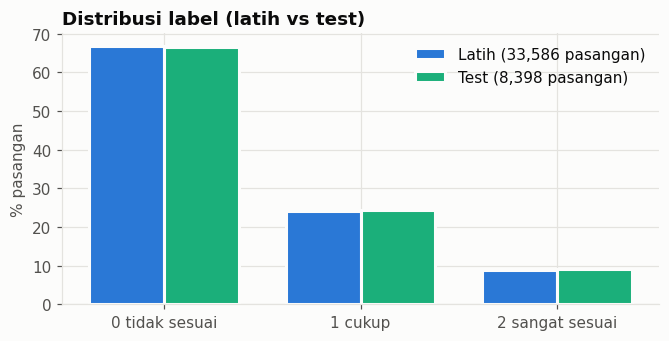

In [2]:
if BUAT_DATA:
    from shared.dataset import generate_category_dataset, load_food_catalog
    generate_category_dataset(load_food_catalog(os.path.join(ROOT, 'data', 'nutrition.csv')), KATEGORI, JUMLAH_PROFIL)

df_train = pd.read_csv(os.path.join(data_dir(KATEGORI), 'train_data.csv'))
df_test = pd.read_csv(os.path.join(data_dir(KATEGORI), 'test_data.csv'))
display(pd.DataFrame({
    'baris': [len(df_train), len(df_test)],
    'profil': [df_train['profile_id'].nunique(), df_test['profile_id'].nunique()],
    'makanan unik': [df_train['food_name'].nunique(), df_test['food_name'].nunique()],
    'baris makanan baru': [int(df_train['is_new_food'].sum()), int(df_test['is_new_food'].sum())],
}, index=['Latih', 'Test']))
grafik.distribusi_label(df_train, df_test)

## 2. Latih model

Validasi silang, model final, pembanding gradient boosting, dan kurva belajar (sekitar 1-2 menit).

In [3]:
h = latih_kategori(KATEGORI)

  NUTRISCALE AI — MODEL UMUM (pemilik: Muel)
  Logistic Regression multinomial | skor = (P(cukup) + 2 * P(sangat sesuai)) / 2



[UMUM] Memuat Dataset:
  - Training samples : 33586 baris (560 profil)
  - Testing samples  : 8398 baris (140 profil baru, Held-Out)
  - Distribusi label : {0: 0.668, 1: 0.242, 2: 0.09}
  - Fitur input      : 99 fitur (model.FEATURE_COLS)


  GroupKFold (5 fold): kappa 0.8923 ± 0.0029 | macro-F1 latih 0.8633 vs validasi 0.8576 ± 0.0050 | NDCG@5 0.9797


  Test (profil baru): Acc 0.9125 | macro-F1 0.8662 | kappa 0.8937
  Macro precision 0.8747 | macro recall 0.8588
    Kelas 0: precision 0.9574 | recall 0.9586 | F1 0.9580 | n=5584
    Kelas 1: precision 0.8124 | recall 0.8355 | F1 0.8238 | n=2042
    Kelas 2: precision 0.8543 | recall 0.7824 | F1 0.8168 | n=772
  Confusion matrix (baris=asli, kolom=prediksi): [[5353, 226, 5], [238, 1706, 98], [0, 168, 604]]
  NDCG@5  model 0.9801 | formula lama 0.6850 | acak 0.5406
  Subset makanan baru (1289 baris): macro-F1 0.8669 | kappa 0.8987
  Pasangan konflik yang tetap diberi label > 0 oleh model saja: 0.08% (di produksi dibuang dulu oleh safety filter)
  Pembanding gradient boosting: Acc 0.9550 | macro-F1 0.9284 | kappa 0.9461 | NDCG@5 0.9912
  Overfitting: macro-F1 latih 0.8626 | validasi CV 0.8576 | test 0.8662 -> tidak overfitting (gradient boosting: selisih +0.0549)
  Koefisien teratas (P2 vs P0): [('natrium_lewat_jauh', -7.2874), ('gula_lewat_jauh', -6.6516), ('any_conflict', -5.9088), ('

## 3. Validasi silang GroupKFold (latih vs validasi)

Tiap lipatan melatih model di 4/5 profil latih dan menguji di 1/5 profil sisanya. Kolom `train_*` = skor pada data
yang dipakai melatih, `val_*` = skor pada profil yang belum pernah dilihat.

,train_accuracy,val_accuracy,train_macro_f1,val_macro_f1,selisih_f1,train_log_loss,val_log_loss,val_weighted_kappa,val_ndcg@5
fold,,,,,,,,,
1,0.9162,0.9080,0.8636,0.8596,0.0040,0.1865,0.2002,0.8898,0.9777
2,0.9132,0.9169,0.8619,0.8637,-0.0018,0.1896,0.1881,0.8968,0.9828
3,0.9137,0.9123,0.8620,0.8598,0.0022,0.1891,0.1920,0.8937,0.9798
4,0.9144,0.9122,0.8649,0.8540,0.0109,0.1884,0.1923,0.8913,0.9801
5,0.9151,0.9095,0.8640,0.8511,0.0129,0.1873,0.1971,0.8900,0.9782


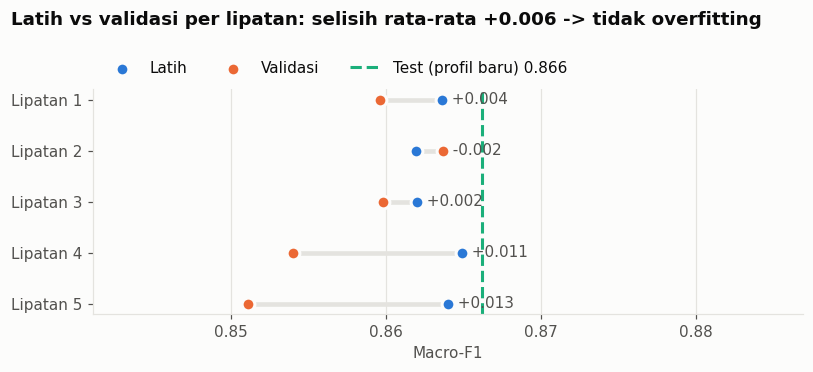

In [4]:
display(grafik.tabel_cv_per_fold(h))
grafik.latih_vs_validasi(h)

## 4. Cek overfitting

Overfitting = model menghafal data latih: skor latih jauh lebih tinggi daripada skor data baru.
Ukurannya adalah **selisih macro-F1 latih − validasi/test**:

| Selisih | Kesimpulan |
|---|---|
| ≤ 0,02 | tidak overfitting |
| ≤ 0,05 | overfitting ringan |
| > 0,05 | overfitting |

Bila skor latih **dan** validasi sama-sama rendah, masalahnya underfitting (model terlalu sederhana), bukan overfitting.
Gradient boosting ditampilkan sebagai pembanding model yang lebih kompleks.

accuracy  macro_f1  weighted_kappa  log_loss
Model               Data                                                                 
Logistic Regression Latih (model final)        0.9141    0.8626          0.8955    0.1887
                    Latih (rata-rata CV)       0.9145    0.8633          0.8960    0.1882
                    Validasi (rata-rata CV)    0.9118    0.8576          0.8923    0.1939
                    Test (profil baru)         0.9125    0.8662          0.8937    0.1983
Gradient boosting   Latih                      0.9905    0.9833          0.9887    0.0522
                    Test (profil baru)         0.9550    0.9284          0.9461    0.1156

Logistic Regression : selisih F1 latih-CV +0.0056, latih-test -0.0036 -> tidak overfitting
Gradient boosting   : selisih F1 latih-test +0.0549 -> overfitting


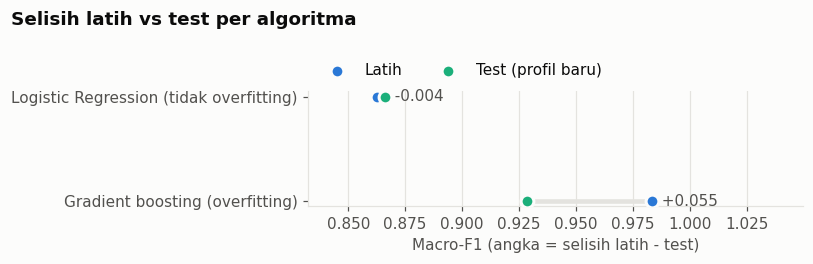

In [5]:
o = h['overfitting']
display(grafik.tabel_overfitting(h))
print(f"Logistic Regression : selisih F1 latih-CV {o['selisih_f1_train_vs_cv']:+.4f}, latih-test {o['selisih_f1_train_vs_test']:+.4f} -> {o['kesimpulan']}")
gb = o['pembanding_gradient_boosting']
print(f"Gradient boosting   : selisih F1 latih-test {gb['selisih_f1_train_vs_test']:+.4f} -> {gb['kesimpulan']}")
grafik.overfitting_lr_vs_gb(h)

### Kurva belajar

Model dilatih ulang dengan 10%..100% profil latih. Bila garis latih dan validasi bertemu di nilai tinggi, model
tidak overfitting; jarak lebar yang menetap = overfitting; keduanya rendah = underfitting.

,n_profil_latih,train_macro_f1,train_std,val_macro_f1,val_std
fraksi,,,,,
0.1,45,0.8893,0.0105,0.8310,0.0044
0.2,90,0.8770,0.0064,0.8479,0.0034
0.4,179,0.8635,0.0042,0.8521,0.0049
0.6,269,0.8652,0.0036,0.8548,0.0034
0.8,358,0.8633,0.0024,0.8559,0.0053
1.0,448,0.8633,0.0012,0.8576,0.0045


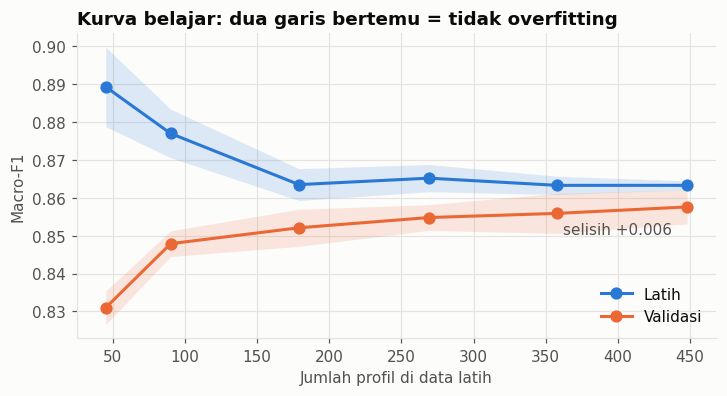

In [6]:
display(pd.DataFrame(h['kurva_belajar']).set_index('fraksi'))
grafik.kurva_belajar(h)

## 5. Test set (profil baru)

Accuracy 0.9125 | macro-F1 0.8662 | weighted kappa 0.8937 | log loss 0.1983
Subset makanan baru (tidak ada di data latih): macro-F1 0.8669 | kappa 0.8987


,precision,recall,f1,support
0 tidak sesuai,0.9574,0.9586,0.9580,5584.0
1 cukup,0.8124,0.8355,0.8238,2042.0
2 sangat sesuai,0.8543,0.7824,0.8168,772.0


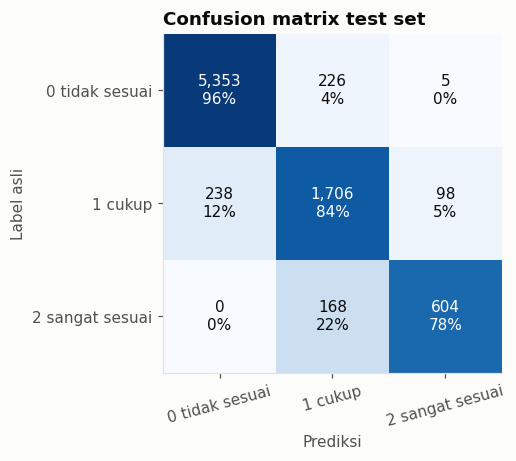

In [7]:
t = h['test']
print(f"Accuracy {t['accuracy']:.4f} | macro-F1 {t['macro_f1']:.4f} | weighted kappa {t['weighted_kappa']:.4f} | log loss {t['log_loss']:.4f}")
nf = h['test_new_food']
print(f"Subset makanan baru (tidak ada di data latih): macro-F1 {nf.get('macro_f1', 0):.4f} | kappa {nf.get('weighted_kappa', 0):.4f}")
display(grafik.tabel_per_kelas(h))
grafik.confusion(h)

## 6. Pembanding

,Accuracy,F1 (macro),Kappa,NDCG@5
Logistic Regression (model),0.9125,0.8662,0.8937,0.9801
Gradient boosting,0.9550,0.9284,0.9461,0.9912
Formula lama,NaN,NaN,NaN,0.6850
Urutan acak,NaN,NaN,NaN,0.5406


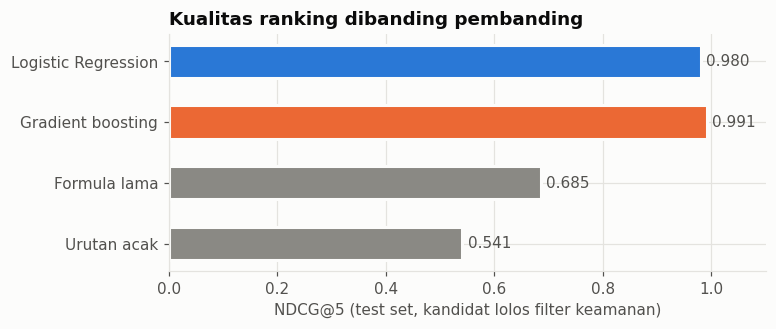

In [8]:
display(grafik.tabel_pembanding(h))
grafik.pembanding_ndcg(h)

## 7. Koefisien model

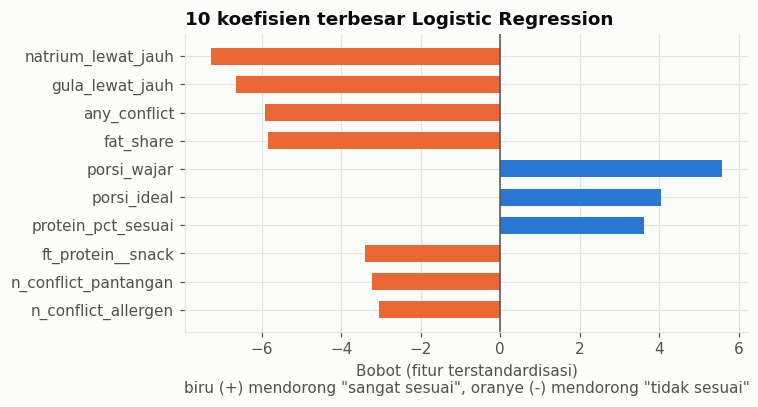

In [9]:
grafik.koefisien(h)

## 8. Uji end-to-end & laporan validasi

Skenario kategori dijalankan lewat pipeline produksi (filter keamanan + model + penyusun menu) memakai katalog
produk Supabase (atau snapshot lokal bila offline). Laporan disimpan ke `outputs/`.

In [10]:
path = validasi_kategori(KATEGORI)
with open(path, encoding='utf-8') as f:
    display(Markdown(f.read()))

[Pipeline] Memuat data makanan dari http://localhost:3000/api/products...


[Pipeline] Sukses memuat data makanan dari Next.js API (50 item).
[Pipeline] OK: 46 makanan siap dengan deteksi alergen & fitur ML.
[UMUM] Acc 0.9125 | Prec 0.8747 | Recall 0.8588 | F1 0.8662 | Kappa 0.8937
[UMUM] Pelanggaran alergen/BLOKIR/tekstur: 0/0/0
[UMUM] Laporan: D:\Semester 6\Proyek Perangkat Lunak I\AINutriScale\ai_recommendation_railway\umum\outputs\laporan_validasi_umum.md


# Laporan Validasi Model UMUM

- Pemilik: **Muel**
- Metode: Logistic Regression multinomial (label 0/1/2), metode dan konfigurasi sama dengan 3 kategori lain (config hash `7ec1c77b29e130d2`)
- Data: 560 profil latih (33586 pasangan), 140 profil uji baru (8398 pasangan); split per profil
- Evaluasi: validasi silang GroupKFold 5 lipatan pada data latih + test set profil baru (dipakai sekali untuk model final)
- Tanggal laporan: 2026-11-09

## 1. Metrik test set (profil baru)

| Accuracy | Precision (macro) | Recall (macro) | F1 (macro) | Weighted kappa | NDCG@5 | NDCG@10 |
|---|---|---|---|---|---|---|
| 0.9125 | 0.8747 | 0.8588 | 0.8662 | 0.8937 | 0.9801 | 0.9857 |

## 2. Validasi silang GroupKFold (5 lipatan, data latih)

| Metrik (validasi) | Rata-rata | Simpangan baku |
|---|---|---|
| accuracy | 0.9118 | 0.0034 |
| macro_f1 | 0.8576 | 0.0050 |
| weighted_kappa | 0.8923 | 0.0029 |
| log_loss | 0.1939 | 0.0047 |
| ndcg@5 | 0.9797 | 0.0020 |

## 3. Per kelas

| Kelas | Precision | Recall | F1 | Jumlah |
|---|---|---|---|---|
| 0 tidak cocok | 0.9574 | 0.9586 | 0.9580 | 5584 |
| 1 cukup | 0.8124 | 0.8355 | 0.8238 | 2042 |
| 2 sangat cocok | 0.8543 | 0.7824 | 0.8168 | 772 |

Confusion matrix (baris = label asli 0/1/2, kolom = prediksi 0/1/2):

| Asli \ Prediksi | 0 | 1 | 2 |
|---|---|---|---|
| 0 | 5353 | 226 | 5 |
| 1 | 238 | 1706 | 98 |
| 2 | 0 | 168 | 604 |

## 4. Pembanding

| Metode | Accuracy | F1 (macro) | Kappa | NDCG@5 |
|---|---|---|---|---|
| Logistic Regression (model) | 0.9125 | 0.8662 | 0.8937 | 0.9801 |
| Gradient boosting (pembanding) | 0.9550 | 0.9284 | 0.9461 | 0.9912 |
| Formula lama | - | - | - | 0.6850 |
| Urutan acak | - | - | - | 0.5406 |

- Subset makanan baru (tidak ada di data latih): macro-F1 0.8669, kappa 0.8987
- Pasangan konflik yang tetap diberi label > 0 oleh model saja: 0.08% (di produksi dibuang dulu oleh filter keamanan)

## 5. Analisis overfitting

Overfitting = skor data latih jauh lebih tinggi daripada data yang belum pernah dilihat. Batas selisih macro-F1: <= 0.02 tidak overfitting, <= 0.05 overfitting ringan, di atasnya overfitting.

| Model | Data | Accuracy | F1 (macro) | Kappa | Log loss |
|---|---|---|---|---|---|
| Logistic Regression | Latih (model final) | 0.9141 | 0.8626 | 0.8955 | 0.1887 |
| Logistic Regression | Test (profil baru) | 0.9125 | 0.8662 | 0.8937 | 0.1983 |
| Gradient boosting | Latih | 0.9905 | 0.9833 | 0.9887 | 0.0522 |
| Gradient boosting | Test (profil baru) | 0.9550 | 0.9284 | 0.9461 | 0.1156 |

- Macro-F1 GroupKFold: latih 0.8633 vs validasi 0.8576 (selisih +0.0056)
- Macro-F1 model final: latih 0.8626 vs test 0.8662 (selisih -0.0036)
- **Kesimpulan Logistic Regression: tidak overfitting**; gradient boosting: overfitting (selisih +0.0549)

Per lipatan GroupKFold:

| Lipatan | F1 latih | F1 validasi | Selisih | Log loss latih | Log loss validasi |
|---|---|---|---|---|---|
| 1 | 0.8636 | 0.8596 | +0.0040 | 0.1865 | 0.2002 |
| 2 | 0.8619 | 0.8637 | -0.0018 | 0.1896 | 0.1881 |
| 3 | 0.8620 | 0.8598 | +0.0022 | 0.1891 | 0.1920 |
| 4 | 0.8649 | 0.8540 | +0.0109 | 0.1884 | 0.1923 |
| 5 | 0.8640 | 0.8511 | +0.0129 | 0.1873 | 0.1971 |

Kurva belajar (macro-F1, rata-rata 5 lipatan GroupKFold):

| Porsi data latih | Profil | F1 latih | F1 validasi | Selisih |
|---|---|---|---|---|
| 10% | 45 | 0.8893 | 0.8310 | +0.0583 |
| 20% | 90 | 0.8770 | 0.8479 | +0.0291 |
| 40% | 179 | 0.8635 | 0.8521 | +0.0114 |
| 60% | 269 | 0.8652 | 0.8548 | +0.0104 |
| 80% | 358 | 0.8633 | 0.8559 | +0.0074 |
| 100% | 448 | 0.8633 | 0.8576 | +0.0057 |

## 6. Koefisien teratas (arah sangat cocok vs tidak cocok)

| Fitur | Bobot |
|---|---|
| natrium_lewat_jauh | -7.2874 |
| gula_lewat_jauh | -6.6516 |
| any_conflict | -5.9088 |
| fat_share | -5.8315 |
| porsi_wajar | 5.5933 |
| porsi_ideal | 4.0387 |
| protein_pct_sesuai | 3.6289 |
| ft_protein__snack | -3.4011 |
| n_conflict_pantangan | -3.2174 |
| n_conflict_allergen | -3.0481 |

## 7. Uji end-to-end (filter keamanan + model + penyusun menu, katalog Supabase)

| Skenario | Item | Kandidat lolos | Alergen | BLOKIR | Tekstur | Skor rata-rata | Latensi (ms) |
|---|---|---|---|---|---|---|---|
| Dewasa Umum Obesitas | 11 | 38 | 0 | 0 | 0 | 66.5 | 70.2 |
| Dewasa Umum Underweight | 11 | 46 | 0 | 0 | 0 | 71.8 | 72.8 |

**Dewasa Umum Obesitas**: pagi: karbo: Whole Wheat Bread, lauk: Tilapia Fish, buah/sayur: Banana; snack_pagi: selingan: Strawberry Yogurt; siang: karbo: Oatmeal, lauk: Fresh Chicken Breast, sayur: Sweet Potato; snack_sore: selingan: Ajwa Dates; malam: karbo: Organic Brown Rice, lauk: Salmon Fillet, sayur: Broccoli

**Dewasa Umum Underweight**: pagi: karbo: Organic Brown Rice, lauk: Lentils, buah/sayur: Sweet Potato; snack_pagi: selingan: Baked Potato Chips; siang: karbo: Quinoa, lauk: Kidney Beans, sayur: Mustard Greens; snack_sore: selingan: Ajwa Dates; malam: karbo: Oatmeal, lauk: Fresh Chicken Breast, sayur: Red Bell Pepper

## 8. Catatan

Data sintetis dan label dari rubrik kategori (umum/ai_models/rubrik.py). Angka di atas mengukur seberapa baik model meniru rubrik, bukan hasil uji klinis. Karena data latih dan test dibuat dari rubrik yang sama, selisih latih-test yang kecil membuktikan model tidak menghafal profil/makanan tertentu, tetapi belum membuktikan kecocokan dengan pengguna nyata. Diperlukan gold set ahli gizi (minimal 300 pasangan) sebelum klaim klinis.
